# Pizza heat distribution: Linear SVM vs. RBF-kernel SVM

A small, reproducible machine-learning demo using **200 fabricated 2D points** on a circular pizza:

- **Class 0 — cold:** the central circle.
- **Class 1 — hot:** the outer ring.
- **Features:** `x` and `y` coordinates only.
- **Split:** 20% training data and 80% test data, stratified by class.

A straight line cannot represent a circular boundary well. The RBF (radial basis function) kernel lets an SVM form a nonlinear boundary by implicitly comparing points in a richer feature space.

> The data are synthetic and are only for demonstrating classification, not measured microwave temperatures.

### Requirements

Run in an environment with `numpy`, `pandas`, `matplotlib`, and `scikit-learn` installed. For example, run `pip install numpy pandas matplotlib scikit-learn` in a terminal if needed.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42
DATA_PATH = Path("pizza_heat_dataset_200.csv")


## 1. Create the fabricated dataset

The points are sampled uniformly over the pizza's circular 2D surface. The center region is labeled cold and the surrounding region hot. The cutoff is chosen to make the two regions roughly balanced by area. This cell also writes the dataset to `pizza_heat_dataset_200.csv` in the notebook's current working directory, so the notebook can run even if you do not keep the separate CSV file.

In [ ]:
# Clear distinction, no outliers

#rng = np.random.default_rng(RANDOM_STATE)
#N_POINTS = 200
#PIZZA_RADIUS = 1.0
#COLD_RADIUS = np.sqrt(0.5)

#theta = rng.uniform(0, 2 * np.pi, N_POINTS)
# sqrt(U) makes samples uniform by area, rather than concentrated near the centre.
#radius = PIZZA_RADIUS * np.sqrt(rng.uniform(0, 1, N_POINTS))
#x = radius * np.cos(theta)
#y = radius * np.sin(theta)

# 0 = cold centre, 1 = hot outer ring
#class_id = (radius > COLD_RADIUS).astype(int)
#class_label = np.where(class_id == 0, "cold", "hot")

#df = pd.DataFrame({
#    "x": x,
#    "y": y,
#    "radius": radius,          # descriptive only; not used as a model feature
#    "class_id": class_id,
#    "class_label": class_label,
#})
#df.to_csv(DATA_PATH, index=False, float_format="%.8f")

#print(f"Saved {len(df)} points to: {DATA_PATH.resolve()}")
#display(df.head())
#print("\nClass counts:")
#display(df["class_label"].value_counts().rename_axis("class_label").to_frame("count"))

# With outliers (A hotter center)
rng = np.random.default_rng(RANDOM_STATE)

N_POINTS = 200
PIZZA_RADIUS = 1.0
COLD_RADIUS = np.sqrt(0.5)

theta = rng.uniform(0, 2 * np.pi, N_POINTS)

# Uniform sampling across the pizza surface
radius = PIZZA_RADIUS * np.sqrt(rng.uniform(0, 1, N_POINTS))
x = radius * np.cos(theta)
y = radius * np.sin(theta)

# 0 = cold centre, 1 = hot outer ring
class_id = (radius > COLD_RADIUS).astype(int)

N_HOT_CENTER_OUTLIERS = 35

# Find all points that are normally labelled cold
cold_center_indices = np.flatnonzero(radius <= COLD_RADIUS)

# Randomly select 35 of these points
outlier_indices = rng.choice(
    cold_center_indices,
    size=min(N_HOT_CENTER_OUTLIERS, len(cold_center_indices)),
    replace=False
)

# Flip their labels from cold (0) to hot (1)
class_id[outlier_indices] = 1

# Create the same class labels as before
class_label = np.where(class_id == 0, "cold", "hot")

# Create the same DataFrame as before
df = pd.DataFrame({
    "x": x,
    "y": y,
    "radius": radius,
    "class_id": class_id,
    "class_label": class_label,
})

# Save to the same CSV file
df.to_csv(DATA_PATH, index=False, float_format="%.8f")

print(f"Saved {len(df)} points to: {DATA_PATH.resolve()}")
print(f"Hot outliers added to centre: {len(outlier_indices)}")

display(df.head())

print("\nClass counts:")
display(
    df["class_label"]
    .value_counts()
    .rename_axis("class_label")
    .to_frame("count")
)

Saved 200 points to: /content/pizza_heat_dataset_200.csv
Hot outliers added to centre: 35


,x,y,radius,class_id,class_label
0,0.132214,-0.871736,0.881706,1,hot
1,-0.914005,0.369352,0.985813,1,hot
2,0.446240,-0.549191,0.707631,1,hot
3,-0.123172,-0.358784,0.379338,1,hot
4,0.097980,0.065850,0.118052,0,cold



Class counts:


,count
class_label,
hot,137
cold,63


## 2. Plot the synthetic pizza heat classes

Each dot is one fabricated measurement location. The dashed circle shows the rule used to create the labels.

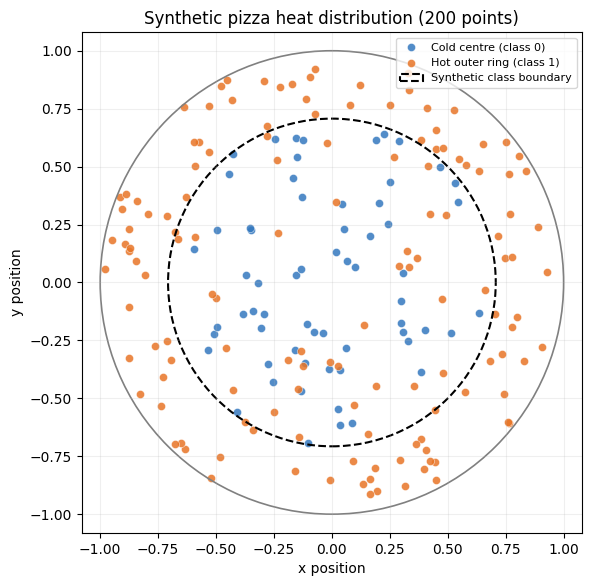

In [ ]:
class_colors = {0: "#3478bf", 1: "#e87527"}
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for label_id, label_name in [(0, "Cold centre (class 0)"), (1, "Hot outer ring (class 1)")]:
    subset = df[df["class_id"] == label_id]
    ax.scatter(subset["x"], subset["y"], s=34, alpha=0.85,
               color=class_colors[label_id], label=label_name, edgecolor="white", linewidth=0.35)
ax.add_patch(plt.Circle((0, 0), PIZZA_RADIUS, fill=False, color="gray", linewidth=1.2))
ax.add_patch(plt.Circle((0, 0), COLD_RADIUS, fill=False, color="black", linestyle="--", linewidth=1.5,
                        label="Synthetic class boundary"))
ax.set(title="Synthetic pizza heat distribution (200 points)", xlabel="x position", ylabel="y position")
ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=8)
plt.show()


## 3. Make the 20/80 train-test split

The model sees only `x` and `y`. We leave `radius` and `class_label` out of the features to avoid giving the model the answer directly. `stratify=y` keeps the class proportions similar in both splits.

In [ ]:
X = df[["x", "y"]]
y = df["class_id"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.80,       # 80% test, therefore 20% train
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Total points: {len(df)}")
print(f"Training points: {len(X_train)} ({len(X_train) / len(df):.0%})")
print(f"Test points: {len(X_test)} ({len(X_test) / len(df):.0%})")
print("\nTraining class counts:")
print(y_train.map({0: "cold", 1: "hot"}).value_counts())
print("\nTest class counts:")
print(y_test.map({0: "cold", 1: "hot"}).value_counts())


Total points: 200
Training points: 40 (20%)
Test points: 160 (80%)

Training class counts:
class_id
hot     27
cold    13
Name: count, dtype: int64

Test class counts:
class_id
hot     110
cold     50
Name: count, dtype: int64


## 4. Train the two SVM models

Both pipelines standardize the coordinates using training data only.

1. **Linear SVM** (`kernel="linear"`): learns a straight decision boundary.
2. **RBF SVM** (`kernel="rbf"`): allows a nonlinear, radial boundary. `C=10` is used here to make the circle-like pattern easier to fit with this small training set; `gamma="scale"` is scikit-learn's data-dependent default.

In [ ]:
linear_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0),
)

rbf_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10.0, gamma="scale"),
)

models = {
    "Linear SVM": linear_svm,
    "RBF-kernel SVM": rbf_svm,
}

for model in models.values():
    model.fit(X_train, y_train)


## 5. Compare test performance

Accuracy is the fraction of held-out test points classified correctly. The RBF model should generally do much better because the underlying rule is circular rather than linear. Results may vary if you change the random seed or data-generation rule.

In [ ]:
results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
display(results_df.style.format({"test_accuracy": "{:.1%}"}))

for name, model in models.items():
    predictions = model.predict(X_test)
    print(f"\n{name} — confusion matrix (rows=true, columns=predicted; order=[cold, hot])")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))
    print(classification_report(y_test, predictions, labels=[0, 1], target_names=["cold", "hot"], zero_division=0))


,model,test_accuracy
0,RBF-kernel SVM,74.4%
1,Linear SVM,68.8%



Linear SVM — confusion matrix (rows=true, columns=predicted; order=[cold, hot])
[[  0  50]
 [  0 110]]
              precision    recall  f1-score   support

        cold       0.00      0.00      0.00        50
         hot       0.69      1.00      0.81       110

    accuracy                           0.69       160
   macro avg       0.34      0.50      0.41       160
weighted avg       0.47      0.69      0.56       160


RBF-kernel SVM — confusion matrix (rows=true, columns=predicted; order=[cold, hot])
[[27 23]
 [18 92]]
              precision    recall  f1-score   support

        cold       0.60      0.54      0.57        50
         hot       0.80      0.84      0.82       110

    accuracy                           0.74       160
   macro avg       0.70      0.69      0.69       160
weighted avg       0.74      0.74      0.74       160



## 6. Visualize the learned decision boundaries

The black solid line is each model's learned decision boundary. The dashed circle is the ideal circular cutoff used to create the labels. The left panel shows why the linear SVM struggles; the RBF model can approximate a circular boundary.

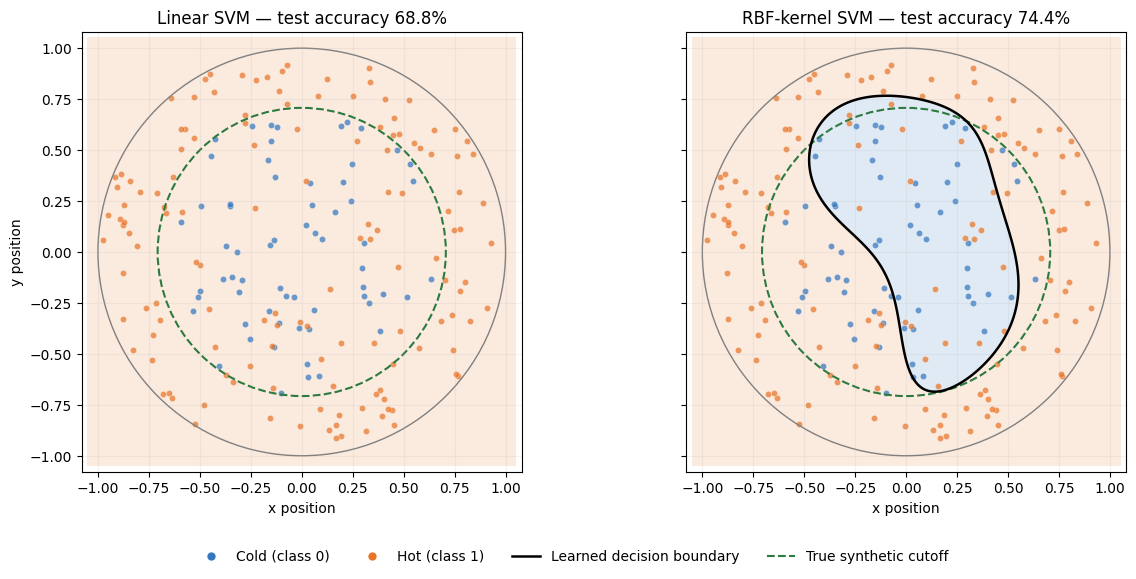

In [ ]:
grid_axis = np.linspace(-1.05, 1.05, 300)
xx, yy = np.meshgrid(grid_axis, grid_axis)
grid_points = pd.DataFrame({"x": xx.ravel(), "y": yy.ravel()})
region_cmap = ListedColormap(["#3478bf", "#e87527"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.7), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    region = model.predict(grid_points).reshape(xx.shape)
    decision = model.decision_function(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5], cmap=region_cmap, alpha=0.15)
    ax.contour(xx, yy, decision, levels=[0], colors="black", linewidths=1.8)

    for label_id in (0, 1):
        subset = df[df["class_id"] == label_id]
        ax.scatter(subset["x"], subset["y"], s=20, color=class_colors[label_id], alpha=0.72,
                   edgecolor="white", linewidth=0.25)
    ax.add_patch(plt.Circle((0, 0), COLD_RADIUS, fill=False, color="#2c7a3f", linestyle="--", linewidth=1.5))
    ax.add_patch(plt.Circle((0, 0), PIZZA_RADIUS, fill=False, color="gray", linewidth=1.0))
    acc = accuracy_score(y_test, model.predict(X_test))
    ax.set_title(f"{name} — test accuracy {acc:.1%}")
    ax.set_xlabel("x position")
    ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("y position")
legend_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=class_colors[0], markersize=7, label="Cold (class 0)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=class_colors[1], markersize=7, label="Hot (class 1)"),
    Line2D([0], [0], color="black", linewidth=1.8, label="Learned decision boundary"),
    Line2D([0], [0], color="#2c7a3f", linestyle="--", linewidth=1.5, label="True synthetic cutoff"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


## Takeaways

- The **linear SVM** can only draw a straight line, so it cannot isolate a cold center from a hot ring very well.
- The **RBF SVM** uses the kernel trick to model a nonlinear boundary resembling a circle without explicitly constructing the high-dimensional features.
- Because the test set is intentionally 80% of the data, only 40 of the 200 examples are used for training. That makes this a simple demonstration, not a tuned production model.

**Try it:** change `COLD_RADIUS`, `RANDOM_STATE`, or the SVM `C` value, then rerun the relevant cells and compare results.